# Introduction

The code is taken from: https://cameronrwolfe.substack.com/i/155023686/routing-tokens-to-experts

## Imports and Configurations

In [1]:
import math
import torch
import torch.nn.functional as F

| Tokens | Experts |
| :--: | :--: |
| 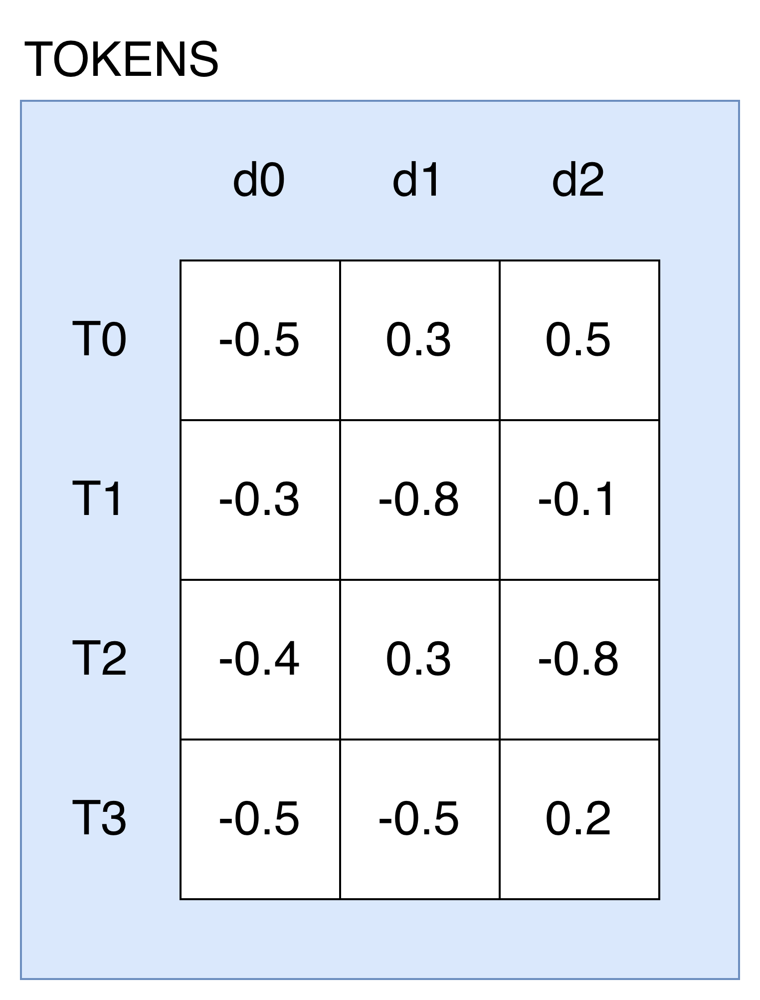 | 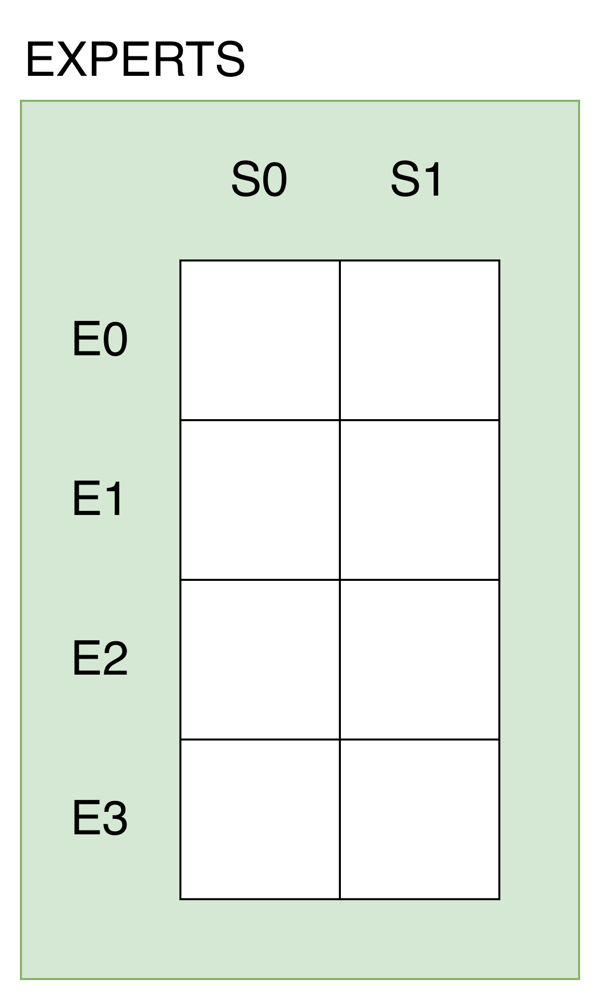 |

In [ ]:
batch_size           = 1       # 1 sequence per batch
tokens_per_sequence  = 4       # 4 tokens per sequence
num_tokens           = batch_size * tokens_per_sequence
num_experts          = 4       # 4 experts (E0, E1, E2, E3)
top_k                = 2       # each token picks top 2 experts
embedding_dim        = 3       # embedding dimension of each token
capacity_factor      = 1.25    # headroom factor for expert capacity - if we want to add more slots

## Build the Input Tokens

In [ ]:
tokens = torch.tensor([
    [
        [-0.5629,  0.3185,  0.5211], # Token 0
        [-0.3495, -0.8894, -0.1209], # Token 1
        [-0.4940,  0.3239, -0.8040], # Token 2
        [-0.5629, -0.0505,  0.2596], # Token 3
    ]
])

print(tokens.shape)

torch.Size([1, 4, 3])


## Compute Router Logits

The router applies a linear projection to compute a score between each token and each expert:

Each entry `router_logits[i, j]` represents token `i`'s affinity for expert `j`. These scores determine which experts each token will be routed to.

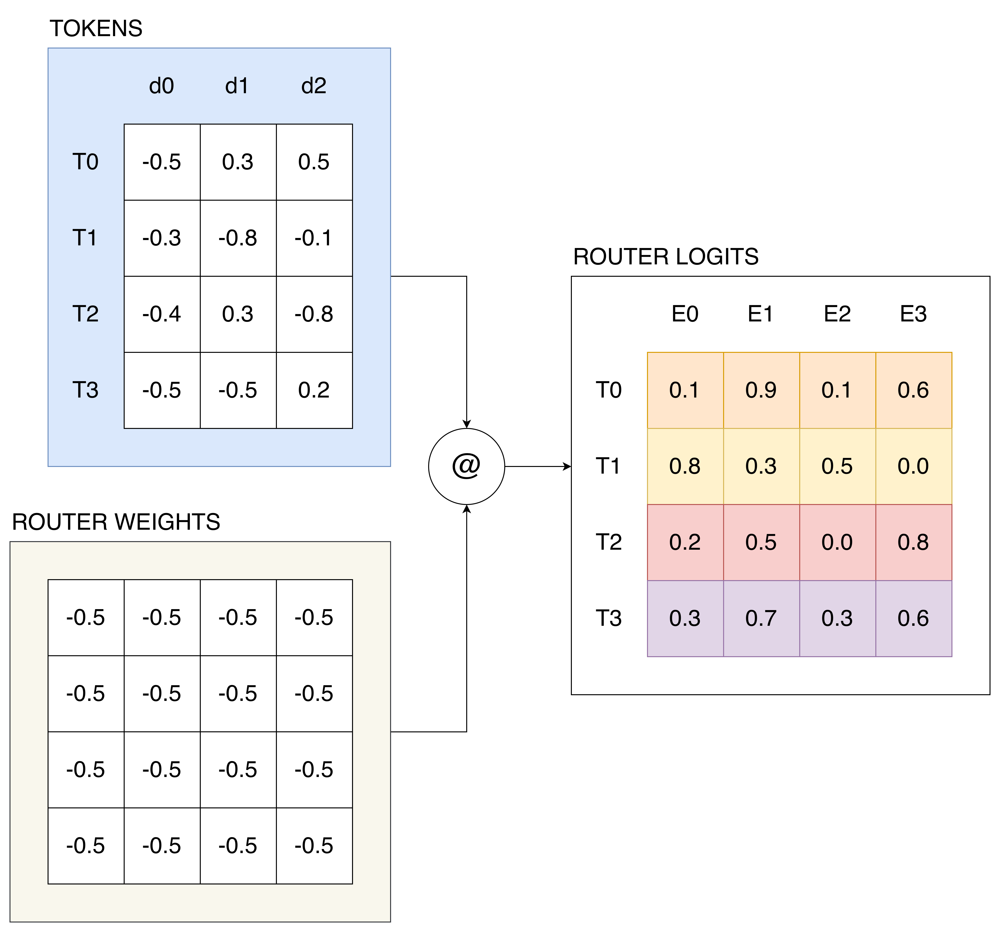

In [ ]:
router = torch.nn.Linear(
    in_features=embedding_dim,
    out_features=num_experts,
    bias=False
)
router_weights = torch.nn.Parameter(
    torch.tensor([
        [-0.6599, -1.3088, -0.5406, -1.2114],
        [-0.6351,  0.1414, -0.4527,  0.3952],
        [-0.1016,  0.2384,  0.0291, -0.2152]
    ]).T
)
router.weight = router_weights

router_logits = router(tokens)  # [batch_size, tokens_per_sequence, num_experts]

print(router_logits)

tensor([[[0.1162, 0.9060, 0.1753, 0.6956],
         [0.8078, 0.3028, 0.5881, 0.0979],
         [0.2020, 0.5007, 0.0970, 0.8995],
         [0.3772, 0.7915, 0.3347, 0.6061]]], grad_fn=<UnsafeViewBackward0>)


## Select Top-K Experts Per Token

Each token selects only `top_k` experts based on the highest logits, rather than attending to all experts.

A naive approach would apply softmax across all experts and let every expert contribute (weighted by probability). However, this defeats the purpose of having multiple experts, every token would require computation from all experts, providing no efficiency gain.

Top-k selection enforces **sparsity**. Each token activates only a small subset of experts. This is what makes MoE computationally attractive, where each token uses only a small % of the total expert capacity while still benefiting from the model's expanded parameter count.

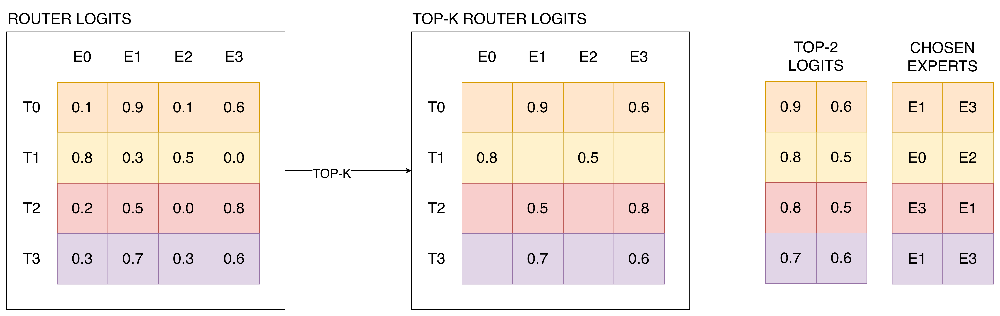

In [ ]:
top_k_scores, top_k_expert_indices = router_logits.topk(k=top_k, dim=-1)

print(top_k_scores)
print(top_k_expert_indices)

tensor([[[0.9060, 0.6956],
         [0.8078, 0.5881],
         [0.8995, 0.5007],
         [0.7915, 0.6061]]], grad_fn=<TopkBackward0>)
tensor([[[1, 3],
         [0, 2],
         [3, 1],
         [1, 3]]])


## Normalized Router Probabilities

The raw logits are unnormalized scores. We now convert them to proper probability weights using softmax (but only over the selected experts).

Why not softmax first, then select? Applying softmax over all experts before selection would let unselected experts influence the final weights through the normalization denominator. The approach here ensures the probability mass is distributed exclusively among the chosen experts.

In the diagram you would notice that the normalized tokens weights do not add up to 1. This is because we have dropped some decimal points for visual simplicity. Refer to the printed tokens for accurate results.

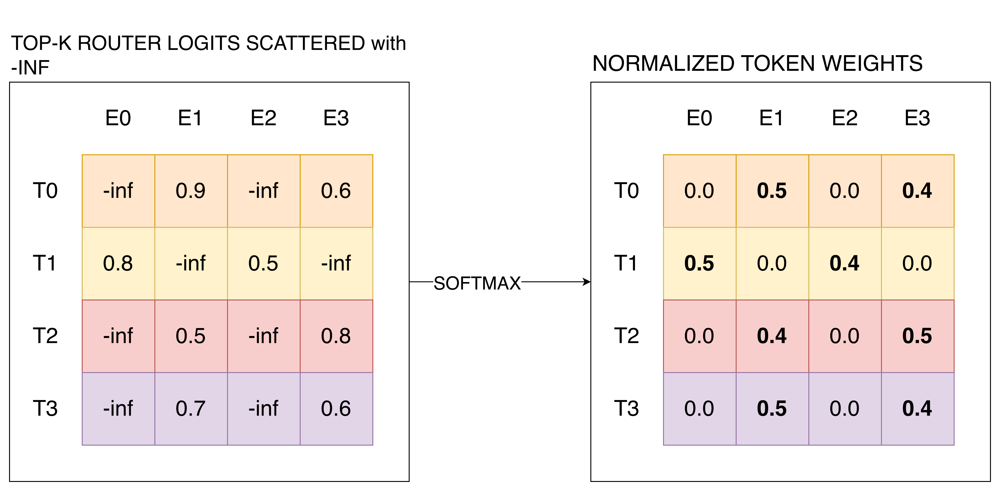

In [ ]:
router_probabilities = torch.full_like(router_logits, float("-inf"))
router_probabilities.scatter_(dim=-1, index=top_k_expert_indices, src=top_k_scores)
router_probabilities = F.softmax(router_probabilities, dim=-1)

print(router_probabilities)

tensor([[[0.0000, 0.5524, 0.0000, 0.4476],
         [0.5547, 0.0000, 0.4453, 0.0000],
         [0.0000, 0.4016, 0.0000, 0.5984],
         [0.0000, 0.5462, 0.0000, 0.4538]]], grad_fn=<SoftmaxBackward0>)


## One-Hot Encode Expert Selections

We now convert chosen expert indices into a binary mask representation. Since each token selects `top_k=2` experts, this produces a multi-hot encoding per token.

For example, if token 0 selected experts E1 (1st choice) and E3 (2nd choice):

```
top_k_expert_indices[0] = [1, 3]

One-hot encoding:
  Choice 0 (E1): [0, 1, 0, 0]
  Choice 1 (E3): [0, 0, 0, 1]
```

We also reshape by priority of choice.

After permutation, the first dimension separates choices by priority:

- `expert_selection_onehot[0]`: All tokens' **first choices** (highest-scoring experts)
- `expert_selection_onehot[1]`: All tokens' **second choices**

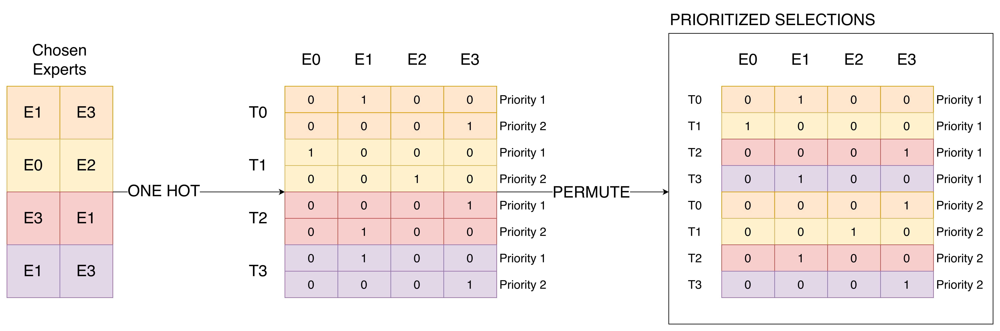

In [ ]:
expert_selection_onehot = F.one_hot(top_k_expert_indices, num_classes=num_experts)
expert_selection_onehot = expert_selection_onehot.view(num_tokens, top_k, num_experts)
expert_selection_onehot = expert_selection_onehot.permute(1, 0, 2)  # [top_k, num_tokens, num_experts]

print(expert_selection_onehot)

tensor([[[0, 1, 0, 0],
         [1, 0, 0, 0],
         [0, 0, 0, 1],
         [0, 1, 0, 0]],

        [[0, 0, 0, 1],
         [0, 0, 1, 0],
         [0, 1, 0, 0],
         [0, 0, 0, 1]]])


## Compute Queue Position for Each Token at Each Position

Each expert can only process a limited number of tokens (its capacity). When multiple tokens select the same expert, we need to assign each token a **position in that expert's queue**. This position determines whether the token fits within capacity or gets dropped.

The cumulative sum counts how many tokens have selected each expert *so far*. Subtracting 1 converts this count into a 0-indexed queue position.

As we scan through the flattened mask (first choices first, then second choices), each time we encounter a 1 for expert `j`, the cumsum increments. The value *before* subtracting 1 tells us "this is the Nth token requesting this expert." After subtracting 1, we get "this token is at position N-1 in the queue."

**Resulting queue structure:**

|          | Position 0 | Position 1 | Position 2 |
|:--------:|:----------:|:----------:|:----------:|
| **E0**   | Token 1    | —          | —          |
| **E1**   | Token 0    | Token 3    | Token 2    |
| **E2**   | Token 1    | —          | —          |
| **E3**   | Token 2    | Token 0    | Token 3    |

**Why first choices come first:** Because we process all first choices before second choices, they claim earlier queue positions. When capacity is enforced, tokens in later positions (typically second choices) are the ones dropped. This prioritizes each token's preferred expert assignment.

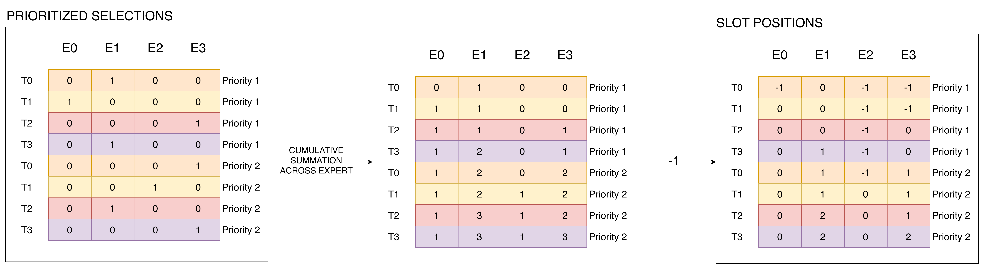

In [ ]:
queue_position_by_expert = expert_selection_onehot.reshape(top_k * num_tokens, num_experts)
queue_position_by_expert = torch.cumsum(queue_position_by_expert, dim=0) - 1  # 0-indexed
queue_position_by_expert = queue_position_by_expert.reshape(top_k, num_tokens, num_experts)

print(queue_position_by_expert)

tensor([[[-1,  0, -1, -1],
         [ 0,  0, -1, -1],
         [ 0,  0, -1,  0],
         [ 0,  1, -1,  0]],

        [[ 0,  1, -1,  1],
         [ 0,  1,  0,  1],
         [ 0,  2,  0,  1],
         [ 0,  2,  0,  2]]])


## Compute Expert Capacity and Enforce Limits

**Expert capacity** is a fixed limit on how many tokens each expert can process in a single batch. This constraint exists for two reasons:

1. **Memory efficiency:** Without a cap, a single popular expert could receive all tokens, causing memory imbalances across devices in distributed training.
2. **Load balancing:** Capacity limits encourage the router to spread tokens across experts rather than overloading a few.

The capacity is computed as:

```
capacity = floor(top_k x capacity_factor x num_tokens / num_experts)
```

For our example: `floor(2 x 1.25 x 4 / 4) = 2` tokens per expert.

**The problem:** Looking at our token queues, some experts are oversubscribed.

|          | Position 0 | Position 1 | Position 2 |
|:--------:|:----------:|:----------:|:----------:|
| **E0**   | Token 1    | —          | —          |
| **E1**   | Token 0    | Token 3    | Token 2    |
| **E2**   | Token 1    | —          | —          |
| **E3**   | Token 2    | Token 0    | Token 3    |

Experts E1 and E3 each have 3 tokens requesting service, but capacity is only 2. The tokens at position 2 (Token 2's request to E1, and Token 3's request to E3) must be **dropped**.

**The consequence:** Dropped tokens lose that expert's contribution to their output. Since we prioritized first choices during queue formation, dropped assignments are always second choices—tokens retain their preferred expert but lose their backup. In severe cases with poor load balancing, some tokens may lose all expert assignments entirely, degrading model performance.

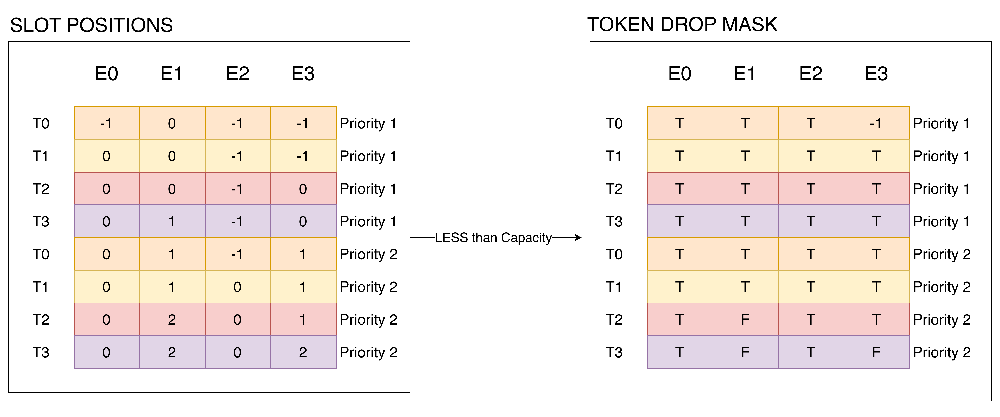

We enforce capacity by zeroing out assignments where a token's queue position meets or exceeds the expert capacity:

**Before capacity enforcement:**

|          | Position 0 | Position 1 | Position 2 |
|:--------:|:----------:|:----------:|:----------:|
| **E0**   | Token 1    | —          | —          |
| **E1**   | Token 0    | Token 3    | Token 2    |
| **E2**   | Token 1    | —          | —          |
| **E3**   | Token 2    | Token 0    | Token 3    |

**After capacity enforcement (capacity = 2):**

|          | Position 0 | Position 1 | Position 2     |
|:--------:|:----------:|:----------:|:--------------:|
| **E0**   | Token 1    | —          | —              |
| **E1**   | Token 0    | Token 3    | ~~Token 2~~    |
| **E2**   | Token 1    | —          | —              |
| **E3**   | Token 2    | Token 0    | ~~Token 3~~    |

**Dropped assignments:**
- Token 2's second choice (E1) — it retains its first choice (E3)
- Token 3's second choice (E3) — it retains its first choice (E1)

Both tokens lose their backup expert but keep their preferred one, which is exactly the graceful degradation we want.

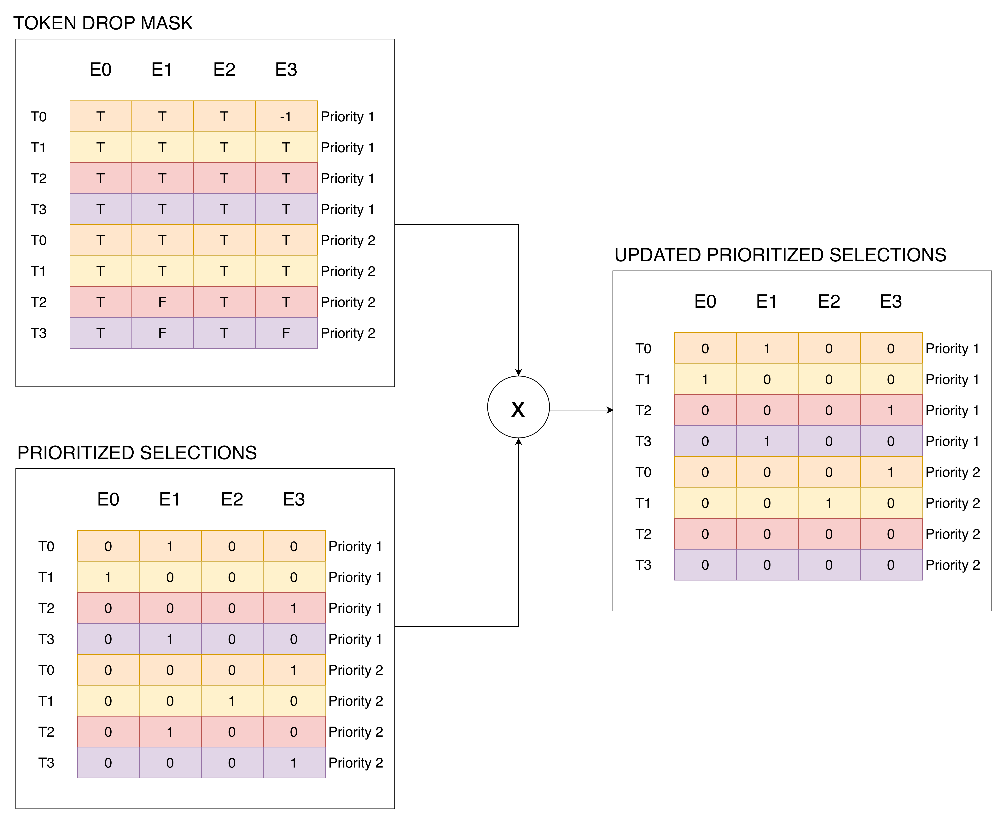

In [ ]:
expert_capacity = math.floor(top_k * capacity_factor * num_tokens / num_experts)
expert_capacity = int(expert_capacity)

within_capacity_mask = queue_position_by_expert < expert_capacity

print(within_capacity_mask)

# Apply capacity mask to keep only valid assignments
valid_assignments = expert_selection_onehot * within_capacity_mask

print(valid_assignments)

tensor([[[ True,  True,  True,  True],
         [ True,  True,  True,  True],
         [ True,  True,  True,  True],
         [ True,  True,  True,  True]],

        [[ True,  True,  True,  True],
         [ True,  True,  True,  True],
         [ True, False,  True,  True],
         [ True, False,  True, False]]])
tensor([[[0, 1, 0, 0],
         [1, 0, 0, 0],
         [0, 0, 0, 1],
         [0, 1, 0, 0]],

        [[0, 0, 0, 1],
         [0, 0, 1, 0],
         [0, 0, 0, 0],
         [0, 0, 0, 0]]])


## Extracting Queue Positions for Each Token's Valid Assignment

We've established which tokens occupy which positions in each expert's queue:

|          | Position 0 | Position 1 |
|:--------:|:----------:|:----------:|
| **E0**   | Token 1    | —          |
| **E1**   | Token 0    | Token 3    |
| **E2**   | Token 1    | —          |
| **E3**   | Token 2    | Token 0    |

But this information is **scattered across the expert dimension**. For each token's each choice, we need to answer: *"What position does this token hold in its selected expert's queue?"*

**The extraction trick:**

The mask acts as a selector. Since each row of `exp_mask` has at most one non-zero entry (the selected expert), multiplying by the rank matrix and summing across experts extracts exactly the rank at the selected position. All other entries are zeroed out by the mask.

**Result:**

| Token   | 1st Choice         | 2nd Choice         |
|:-------:|:------------------:|:------------------:|
| Token 0 | Rank 0 at E1 ✓     | Rank 1 at E3 ✓     |
| Token 1 | Rank 0 at E0 ✓     | Rank 0 at E2 ✓     |
| Token 2 | Rank 0 at E3 ✓     | Dropped (was E1)   |
| Token 3 | Rank 1 at E1 ✓     | Dropped (was E3)   |

**Note on dropped assignments:** Dropped tokens still show a rank value of 0 in the output, but this is meaningless—the corresponding mask entry is zero, so these values will have no effect in subsequent computations.

## Mask Router Probabilities by Valid Assignment

The router probabilities computed earlier contain softmax weights for all top-k selections, but they don't yet reflect capacity constraints. We now apply the expert mask to produce the final routing weights.

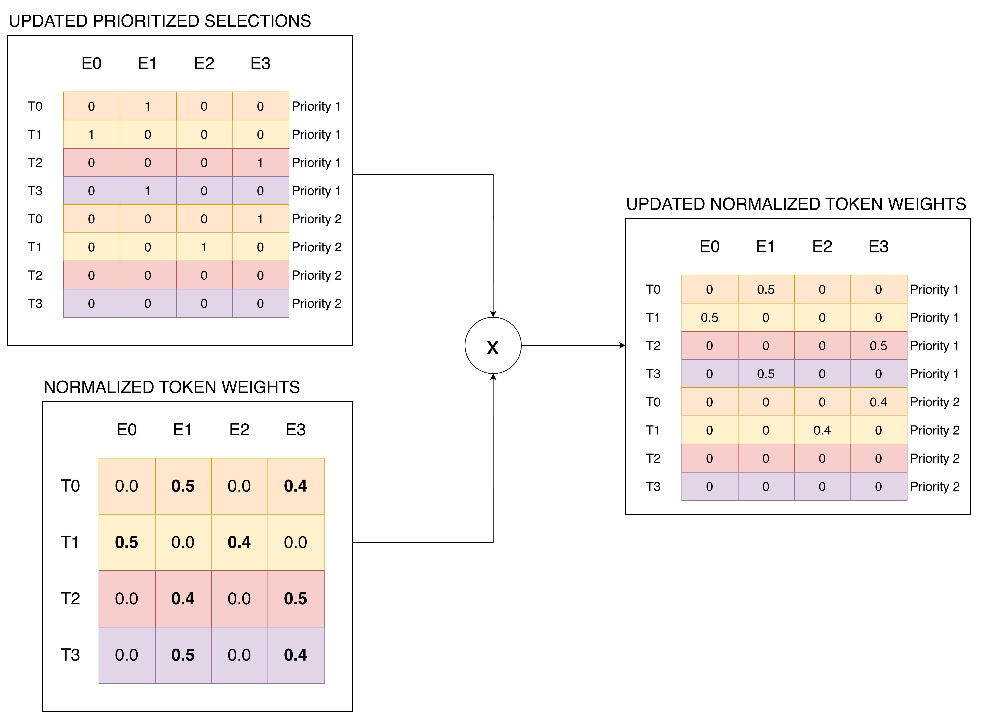

In [ ]:
router_probabilities_flat = router_probabilities.view(num_tokens, num_experts)[None, :]
masked_routing_weights = valid_assignments * router_probabilities_flat

print(masked_routing_weights)

tensor([[[0.0000, 0.5524, 0.0000, 0.0000],
         [0.5547, 0.0000, 0.0000, 0.0000],
         [0.0000, 0.0000, 0.0000, 0.5984],
         [0.0000, 0.5462, 0.0000, 0.0000]],

        [[0.0000, 0.0000, 0.0000, 0.4476],
         [0.0000, 0.0000, 0.4453, 0.0000],
         [0.0000, 0.0000, 0.0000, 0.0000],
         [0.0000, 0.0000, 0.0000, 0.0000]]], grad_fn=<MulBackward0>)


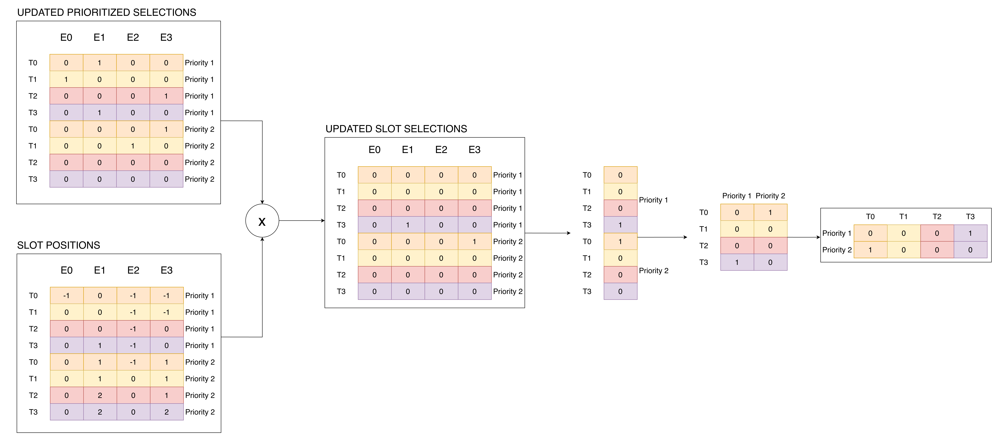

In [ ]:
token_queue_positions = torch.sum(valid_assignments * queue_position_by_expert, dim=-1)

print(token_queue_positions)

tensor([[0, 0, 0, 1],
        [1, 0, 0, 0]])


## One-Hot Encode Queue Positions

So far, we know *which* expert each token is assigned to and *what weight* that assignment carries. But we also need to know *where* within each expert's capacity that token sits. The one-hot encoding converts queue positions into a format suitable for building the final weight matrix.

**What we have:**

| Token   | 1st Choice Queue Position | 2nd Choice Queue Position |
|:-------:|:-------------------------:|:-------------------------:|
| Token 0 | 0                         | 1                         |
| Token 1 | 0                         | 0                         |
| Token 2 | 0                         | 0 (dropped)               |
| Token 3 | 1                         | 0 (dropped)               |

**After one-hot encoding (capacity = 2):**

| Token   | 1st Choice        | 2nd Choice        |
|:-------:|:-----------------:|:-----------------:|
| Token 0 | [1, 0] → pos 0    | [0, 1] → pos 1    |
| Token 1 | [1, 0] → pos 0    | [1, 0] → pos 0    |
| Token 2 | [1, 0] → pos 0    | [1, 0] (ignored)  |
| Token 3 | [0, 1] → pos 1    | [1, 0] (ignored)  |

**Why is this necessary?**

We need to construct a 3D weight tensor of shape `[num_tokens, n_exp, capacity]` that answers: *"For token `i`, at expert `j`, at capacity slot `k`—what is the routing weight?"*

Currently, our information is split across two tensors:
- `router_probabilities[K, num_tokens, n_exp]`: *which expert* and *what weight*
- `token_queue_position[K, num_tokens]`: *which position* in that expert's queue

The one-hot encoding expands the queue position into the capacity dimension, enabling us to combine both tensors through an outer product. This "scatters" each weight to its correct `(expert, position)` coordinate in the final matrix.

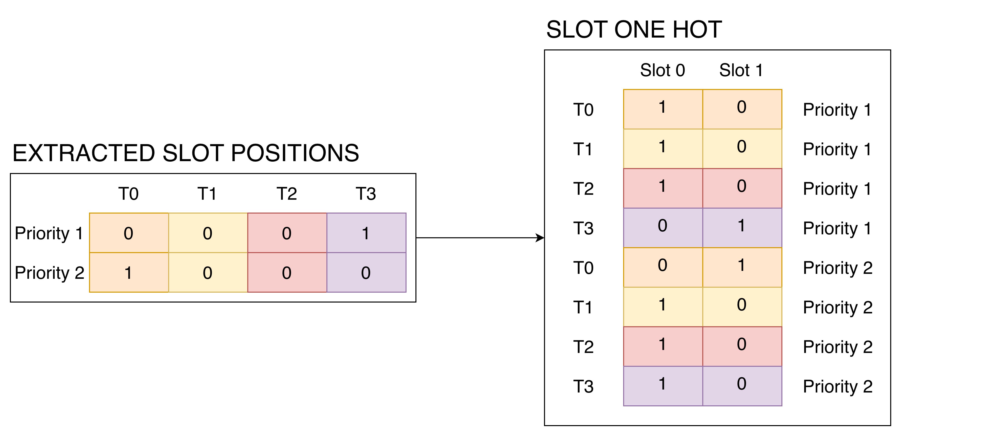

In [ ]:
queue_position_onehot = F.one_hot(token_queue_positions, num_classes=expert_capacity)

print(queue_position_onehot)

tensor([[[1, 0],
         [1, 0],
         [1, 0],
         [0, 1]],

        [[0, 1],
         [1, 0],
         [1, 0],
         [1, 0]]])


## Build Final Weight Matrix

We now combine the expert weights with queue positions to construct a single tensor that encodes: *"For each token, at each expert, at each capacity slot—what is the routing weight?"*

**The mechanics:**

| Tensor                          | Shape                           | Description                              |
|:-------------------------------:|:-------------------------------:|:----------------------------------------:|
| `router_probabilities`                | [K, num_tokens, n_exp]          | Weight at each expert                    |
| `queue_position_onehot`                | [K, num_tokens, capacity]       | One-hot position in expert's queue       |
| `router_probabilities.unsqueeze(3)`   | [K, num_tokens, n_exp, **1**]   | Add capacity dimension                   |
| `queue_position_onehot.unsqueeze(2)`   | [K, num_tokens, **1**, capacity]| Add expert dimension                     |
| Product                         | [K, num_tokens, n_exp, capacity]| Outer product across expert x capacity   |
| Sum over K                      | [num_tokens, n_exp, capacity]   | Merge first and second choices           |

**Why an outer product?**

Each token's assignment involves two pieces of information:
- *Which expert* (a one-hot across `n_exp`)
- *Which position* (a one-hot across `capacity`)

The outer product combines these into a single 2D grid per token, placing the weight at exactly one `(expert, position)` coordinate. All other entries remain zero.

**Concrete example—Token 0:**

Token 0 has:
- 1st choice: E1 with weight 0.55 at position 0
- 2nd choice: E3 with weight 0.45 at position 1

```
1st choice outer product (K=0):
  expert_weights[0, 0] = [0, 0.5, 0, 0]     → expert E1
  token_queue_sc[0, 0] = [1, 0]              → position 0

  Outer product [n_exp, capacity]:
           pos 0   pos 1
      E0 [ 0.00,   0.00 ]
      E1 [ 0.5,   0.00 ]  ← weight lands at (E1, pos 0)
      E2 [ 0.00,   0.00 ]
      E3 [ 0.00,   0.00 ]

2nd choice outer product (K=1):
  expert_weights[1, 0] = [0, 0, 0, 0.4]     → expert E3
  token_queue_sc[1, 0] = [0, 1]              → position 1

  Outer product [n_exp, capacity]:
           pos 0   pos 1
      E0 [ 0.00,   0.00 ]
      E1 [ 0.00,   0.00 ]
      E2 [ 0.00,   0.00 ]
      E3 [ 0.00,   0.4 ]  ← weight lands at (E3, pos 1)

Sum over K (merge choices):
           pos 0   pos 1
      E0 [ 0.00,   0.00 ]
      E1 [ 0.5,   0.00 ]  ← 1st choice
      E2 [ 0.00,   0.00 ]
      E3 [ 0.00,   0.4 ]  ← 2nd choice
```

**The result:** A sparse 3D tensor where each token has non-zero weights at exactly the `(expert, position)` coordinates corresponding to its valid assignments. This structure enables efficient batched computation in the next step—gathering tokens into expert batches and later scattering the results back.

| | Slot 0 | Slot 1 |
| :-: | :--: | :--: |
| E0  | 0.5 x Token 1 |          |
| E1  | 0.5 x Token 0 | 0.5 x Token 3 |
| E2  | 0.4 x Token 1 |          |
| E3  | 0.5 x Token 2 | 0.4 x Token 0 |


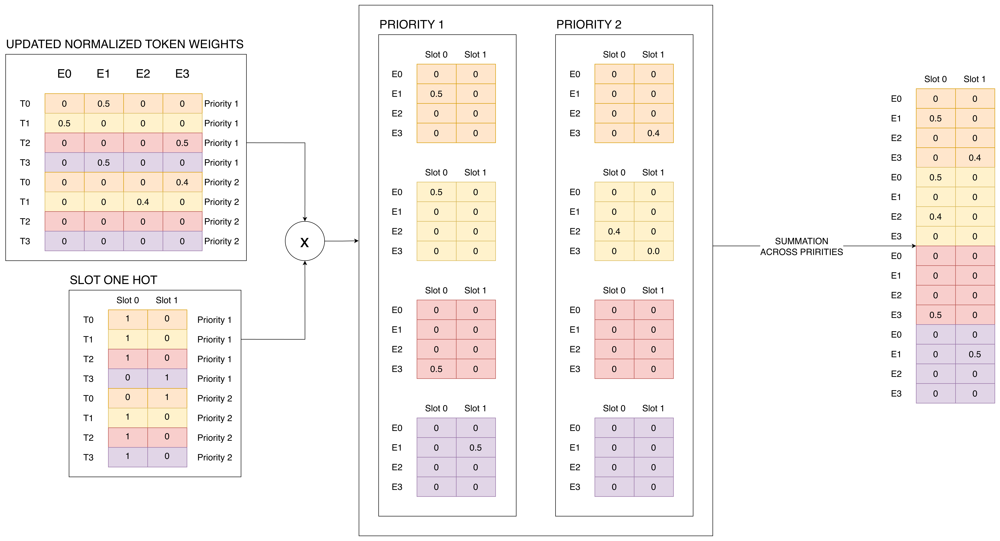

In [ ]:
final_routing_weights = torch.sum(
    masked_routing_weights.unsqueeze(3) * queue_position_onehot.unsqueeze(2),
    dim=0
)

print(final_routing_weights)

tensor([[[0.0000, 0.0000],
         [0.5524, 0.0000],
         [0.0000, 0.0000],
         [0.0000, 0.4476]],

        [[0.5547, 0.0000],
         [0.0000, 0.0000],
         [0.4453, 0.0000],
         [0.0000, 0.0000]],

        [[0.0000, 0.0000],
         [0.0000, 0.0000],
         [0.0000, 0.0000],
         [0.5984, 0.0000]],

        [[0.0000, 0.0000],
         [0.0000, 0.5462],
         [0.0000, 0.0000],
         [0.0000, 0.0000]]], grad_fn=<SumBackward1>)


## Gather Tokens into Expert Batches

With the weight matrix constructed, we now physically group tokens by their assigned experts. Each expert receives a batch of tokens it must process.

**Step-by-step breakdown:**

| Operation                        | Shape                          | Purpose                                      |
|:--------------------------------:|:------------------------------:|:--------------------------------------------:|
| `expert_weights.bool()`          | [num_tokens, n_exp, capacity]  | Convert to binary mask (non-zero → True)     |
| `tokens.view(...)`               | [num_tokens, d]                | Flatten batch dimension                      |
| `expert_mask.permute(1, 2, 0)`   | [n_exp, capacity, num_tokens]  | Reorder to [expert, slot, token]             |
| `@ tokens`                       | [n_exp, capacity, d]           | Gather tokens via matrix multiplication      |

**Why permute?**

The permutation transforms the mask into a **gather matrix** for each expert. After permuting to `[n_exp, capacity, num_tokens]`, each expert has a 2D matrix of shape `[capacity, num_tokens]` where:
- Each row corresponds to a capacity slot
- Each column corresponds to a token
- A `1` at position `(slot, token)` means "pull this token into this slot"

**How matrix multiplication gathers tokens:**

```
gather_matrix @ tokens = expert_batch
[capacity, num_tokens] @ [num_tokens, d] → [capacity, d]
```

Each row of the gather matrix selects (at most) one token via a dot product. A row of all zeros produces a zero vector (empty slot).

**Concrete example—Expert 1's gather matrix:**

Expert 1 has Token 0 at position 0 and Token 3 at position 1:

```
Expert 1's gather matrix [capacity, num_tokens]:
             T0   T1   T2   T3
    pos 0: [  1,   0,   0,   0 ]   ← select Token 0
    pos 1: [  0,   0,   0,   1 ]   ← select Token 3

tokens [num_tokens, d]:
    [-0.5629,  0.3185,  0.5211], # Token 0
    [-0.3495, -0.8894, -0.1209], # Token 1
    [-0.4940,  0.3239, -0.8040], # Token 2
    [-0.5629, -0.0505,  0.2596], # Token 3

Matrix multiplication:
    pos 0: [1,0,0,0] @ tokens = T0 = [-0.5629,  0.3185,  0.5211]
    pos 1: [0,0,0,1] @ tokens = T3 = [-0.5629, -0.0505,  0.2596]

Expert 1's batch [capacity, d]:
    ┌──────────────────────────────────┐
    │ pos 0: [-0.5629,  0.3185,  0.5211]  (Token 0)
    │ pos 1: [-0.5629, -0.0505,  0.2596]  (Token 3)
    └──────────────────────────────────┘
```

**Why this matters:** Each expert now has a fixed-size batch `[capacity, d]` that can be processed independently and in parallel. This uniform shape enables efficient batched computation across all experts, which is critical for performance in distributed MoE implementations.

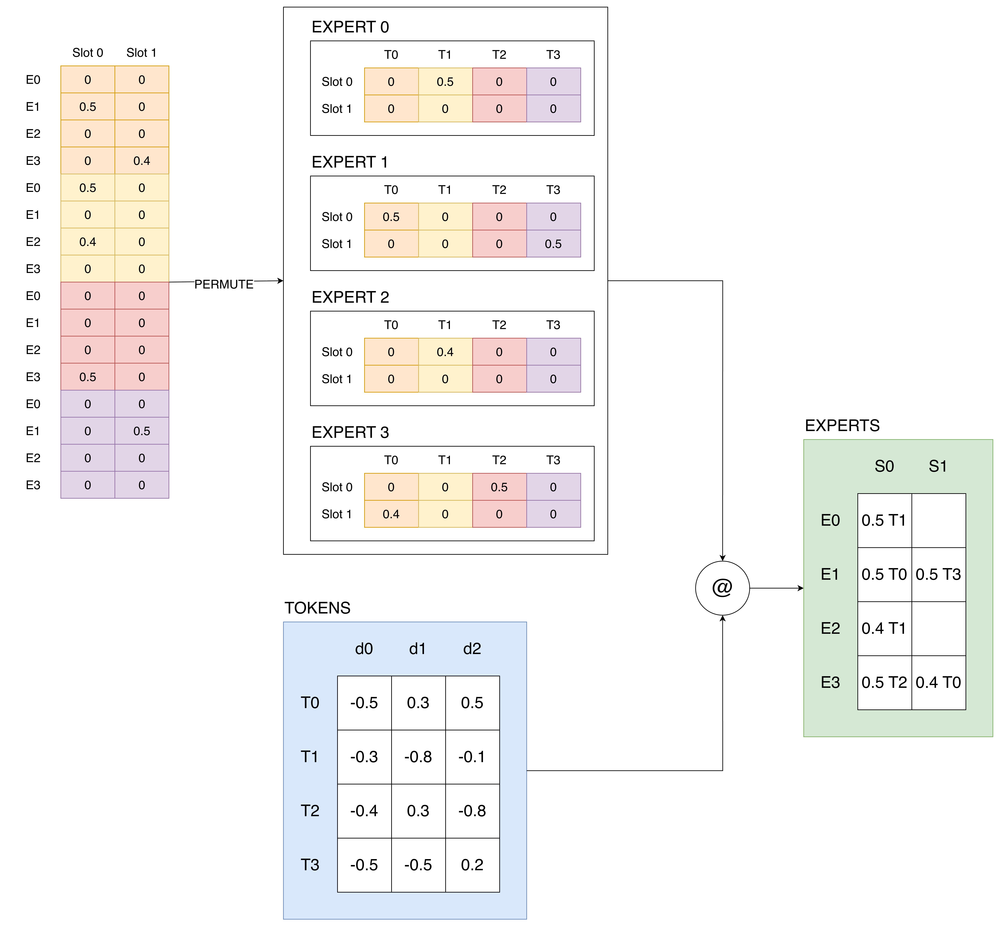

In [ ]:
token_gather_mask = final_routing_weights.bool()
tokens_flat = tokens.view(num_tokens, embedding_dim)

expert_input_batches = token_gather_mask.permute(1, 2, 0).type_as(tokens_flat) @ tokens_flat

print(expert_input_batches)

tensor([[[-0.3495, -0.8894, -0.1209],
         [ 0.0000,  0.0000,  0.0000]],

        [[-0.5629,  0.3185,  0.5211],
         [-0.5629, -0.0505,  0.2596]],

        [[-0.3495, -0.8894, -0.1209],
         [ 0.0000,  0.0000,  0.0000]],

        [[-0.4940,  0.3239, -0.8040],
         [-0.5629,  0.3185,  0.5211]]])
